# 05. Avaliação Prospectiva (Set-Out/2026): Modelo Congelado em 31/08/2026
**Artefato Analítico-Preditivo para Planejamento de Demanda e Mitigação do Desperdício**  
*Mestrado Profissional em Educação Profissional e Tecnológica (ProfEPT) / Gestão Pública*  
**Pesquisador:** Michel Silva de Souza  

---

## Storytelling: O Teste do Modelo no Período Seguinte
Na gestão do restaurante institucional escolar, prever o consumo não é apenas um exercício de minimização de erro numérico: é uma **decisão de política pública** que equilibra dois imperativos constitucionais:
1. **Segurança Alimentar e Nutricional dos Alunos:** Nenhum estudante que comparecer à escola pode ficar sem refeição (tolerância mínima ao déficit).
2. **Eficiência e Zelo com o Erário Público:** Cada refeição produzida a mais e não consumida torna-se desperdício biológico e prejuízo financeiro (R$ 14,00 por refeição).

Este notebook avalia o período seguinte ao usado para treinar e calibrar o modelo:
* **Período Prospectivo (Setembro e Outubro de 2026 - $N=33$ dias):** Modelo ExtraTrees congelado em 31/08/2026, sem retreino, com métricas reprocessadas em 01/11/2026. O modelo é reconstruído com dados até 31/08, e sua especificação difere do ExtraTrees do torneio (`max_features` e início do treino em 2025).

### Como os dias atípicos são tratados
O registro de dia atípico só existe depois do consumo. Por isso, ele tem três usos distintos:
1. **Treino:** o dia fica fora, para não ensinar um padrão que o modelo não tem como prever.
2. **Lags das previsões seguintes:** dias com consumo muito baixo ficam fora, para não derrubar as semanas seguintes.
3. **Avaliação:** o dia continua visível. O resultado principal usa todos os dias, porque a decisão de sexta não sabia do evento, e o recorte sem evento registrado aparece ao lado.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import Image, display

from src.core.config import RESULTADOS
from src.core.safety_margins import PASTA_TABELAS, PASTA_FIGURAS

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["figure.dpi"] = 140


## 1. Resultados de Setembro e Outubro de 2026 ($N=33$ dias)
Resultado principal com o modelo congelado em todos os dias, ao lado do recorte sem evento registrado. O walk-forward aparece apenas como análise de sensibilidade.

=== TABELA 07: DESEMPENHO NO BIMESTRE PROSPECTIVO (SET-OUT/2026) ===


,Configuracao,Regime,Recorte,MAE,WAPE_pct,Sobra_Total_ref,Deficit_Total_ref,Taxa_Deficit_pct,Custo_Potencial_Sobras_RS
0,Nutricionista Institucional,Resultado principal,Todos os dias (N=33),39.48,21.90,972,331,33.3,13608.0
1,ExtraTrees Congelado em 31/08,Resultado principal,Todos os dias (N=33),34.00,18.86,722,400,60.6,10108.0
2,Híbrido 50/50 Congelado,Resultado principal,Todos os dias (N=33),34.36,19.06,811,323,48.5,11354.0
3,Híbrido Congelado + Margem P85,Resultado principal,Todos os dias (N=33),43.48,24.12,1308,127,15.2,18312.0
4,Nutricionista Institucional,Resultado principal,Sem evento registrado (N=28),22.14,11.10,289,331,39.3,4046.0
5,ExtraTrees Congelado em 31/08,Resultado principal,Sem evento registrado (N=28),18.29,9.16,112,400,71.4,1568.0
6,Híbrido 50/50 Congelado,Resultado principal,Sem evento registrado (N=28),17.36,8.70,163,323,57.1,2282.0
7,Híbrido Congelado + Margem P85,Resultado principal,Sem evento registrado (N=28),24.36,12.21,555,127,17.9,7770.0
8,Nutricionista Institucional,Resultado principal,Dias de enchente (N=5),136.60,188.67,683,0,0.0,9562.0
9,ExtraTrees Congelado em 31/08,Resultado principal,Dias de enchente (N=5),122.00,168.51,610,0,0.0,8540.0


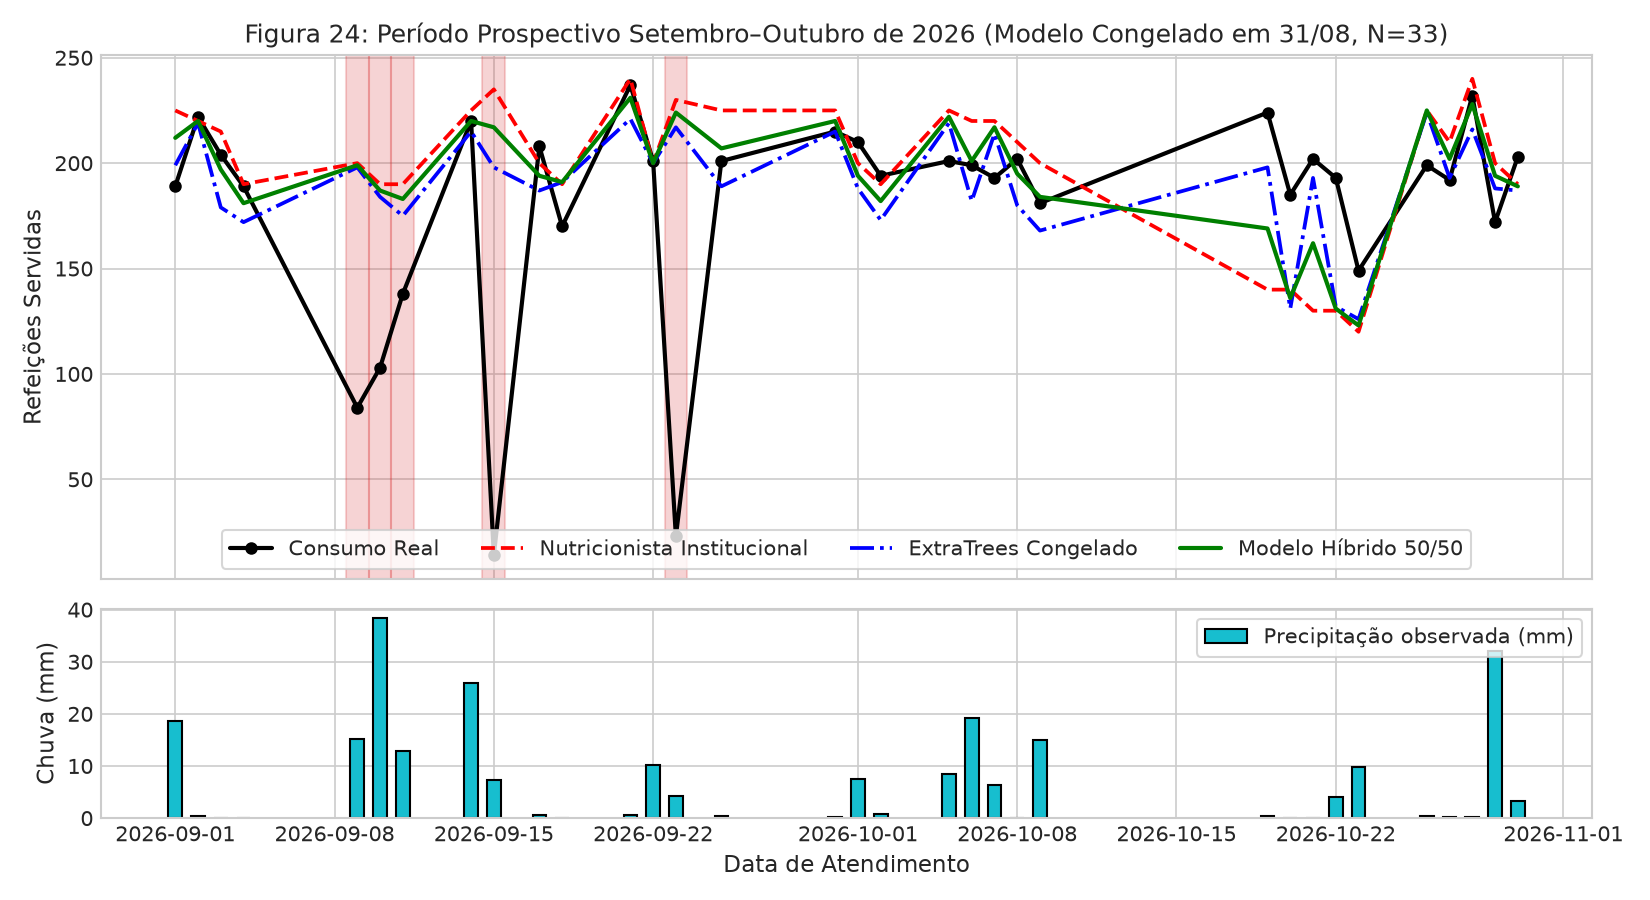

In [2]:
tabela_07 = pd.read_csv(PASTA_TABELAS / "tabela_07_desempenho_prospectivo_set_out.csv", sep=";")
print("=== TABELA 07: DESEMPENHO NO BIMESTRE PROSPECTIVO (SET-OUT/2026) ===")
display(tabela_07[["Configuracao", "Regime", "Recorte", "MAE", "WAPE_pct", "Sobra_Total_ref", "Deficit_Total_ref", "Taxa_Deficit_pct", "Custo_Potencial_Sobras_RS"]])
display(Image(filename=str(PASTA_FIGURAS / "figura_24_serie_temporal_bimestre_set_out_chuva_vs_consumo.png")))


### 1.1. Setembro: Dias sem Evento Registrado vs. Dias de Enchente
Decomposição de setembro. Nenhum método antecipou as enchentes: as previsões continuaram muito acima do consumo observado. A lista de datas foi definida depois do fato.

=== TABELA 08: SETEMBRO DE 2026, DIAS SEM EVENTO VS. ENCHENTES ===


,Recorte,Metodo,MAE,RMSE,WAPE_pct,Sobra_Total_ref,Deficit_Total_ref,Custo_Potencial_Sobras_RS
0,Dias sem evento registrado (N=11),Nutricionista Institucional,11.00,15.37,5.36,110,11,1540.0
1,Dias sem evento registrado (N=11),ExtraTrees Congelado em 31/08,11.91,14.56,5.81,31,100,434.0
2,Dias sem evento registrado (N=11),Híbrido 50/50 Congelado,8.45,11.20,4.12,55,38,770.0
3,Dias sem evento registrado (N=11),Híbrido Congelado + Margem P85,22.55,25.13,10.99,248,0,3472.0
4,Dias de enchente (N=5),Nutricionista Institucional,136.60,151.93,188.67,683,0,9562.0
5,Dias de enchente (N=5),ExtraTrees Congelado em 31/08,122.00,135.95,168.51,610,0,8540.0
6,Dias de enchente (N=5),Híbrido 50/50 Congelado,129.60,144.16,179.01,648,0,9072.0
7,Dias de enchente (N=5),Híbrido Congelado + Margem P85,150.60,163.30,208.01,753,0,10542.0


,data,consumo,plano_nutricionista,previsao_ia,previsao_hibrido,previsao_ia_com_clima,previsao_chuva_mm,oraculo_chuva_mm
0,2026-09-09,84.0,200.0,198.0,199.0,195.0,30.5,15.1
1,2026-09-10,103.0,190.0,184.0,187.0,173.0,19.6,38.3
2,2026-09-11,138.0,190.0,175.0,183.0,167.0,1.6,12.8
3,2026-09-15,14.0,235.0,198.0,217.0,199.0,5.2,7.4
4,2026-09-23,23.0,230.0,217.0,224.0,216.0,4.8,4.3


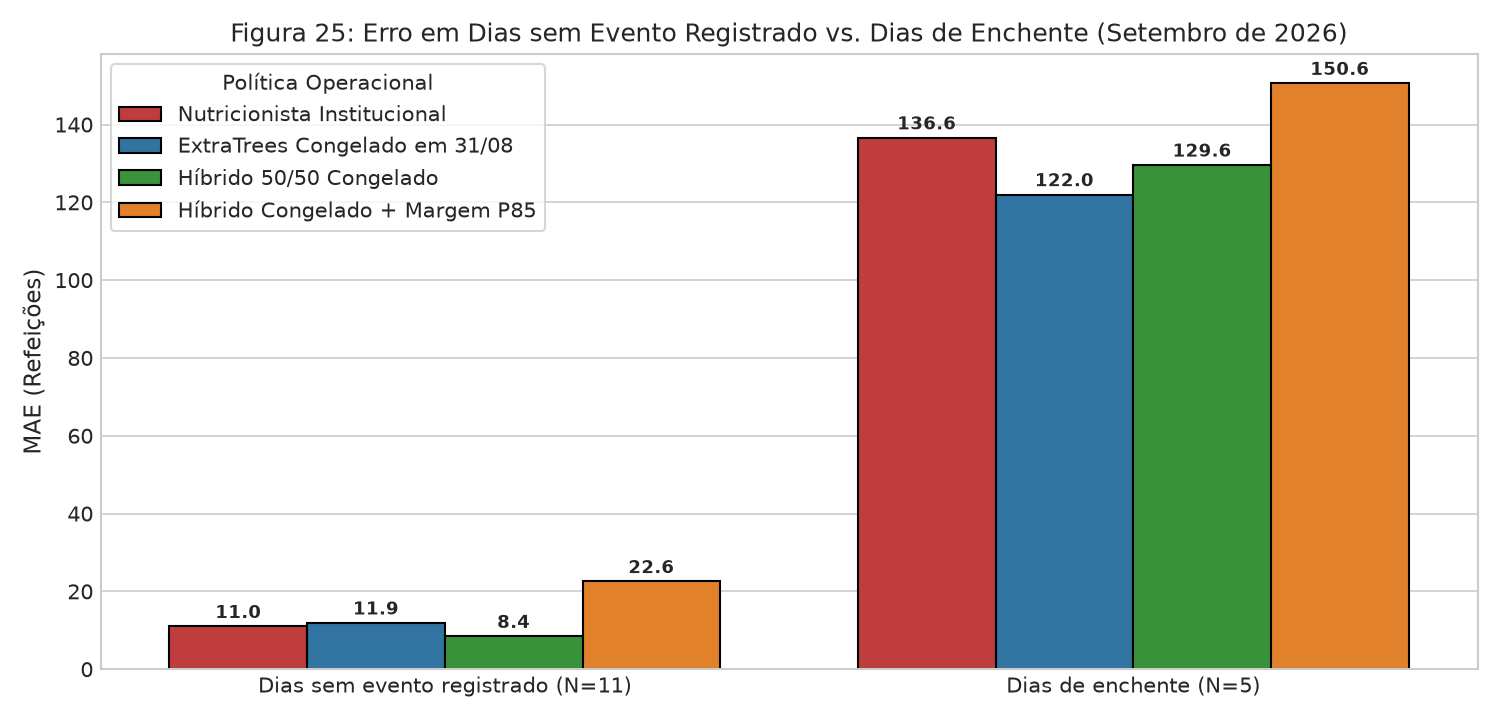

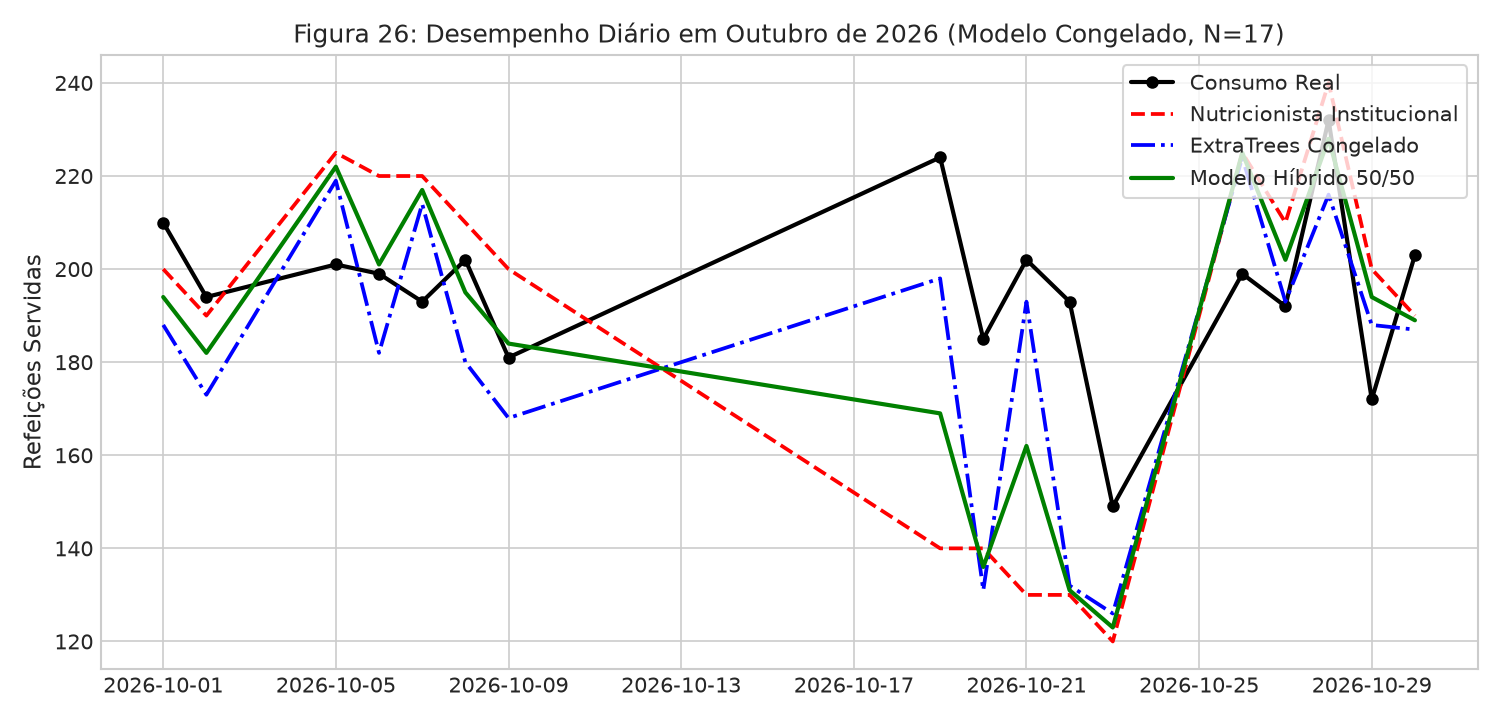

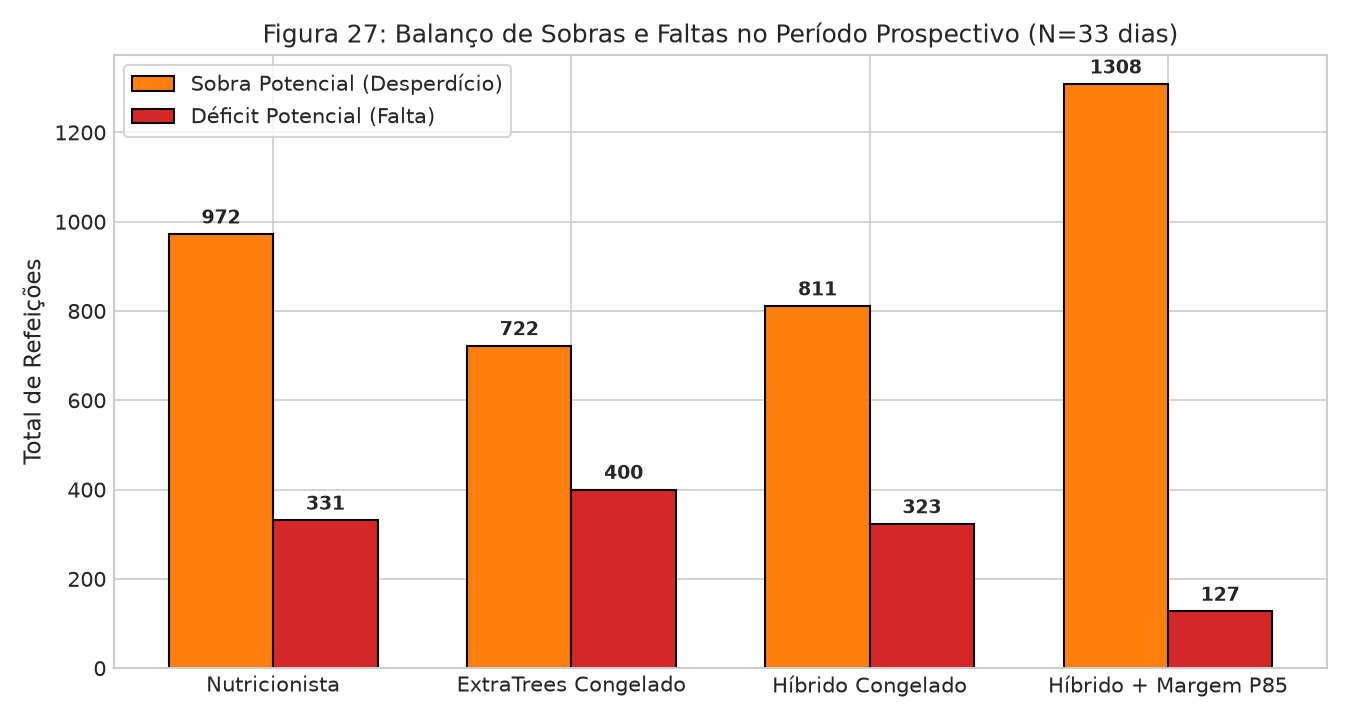

In [3]:
tabela_08 = pd.read_csv(PASTA_TABELAS / "tabela_08_resiliencia_climatica_setembro_enchentes.csv", sep=";")
print("=== TABELA 08: SETEMBRO DE 2026, DIAS SEM EVENTO VS. ENCHENTES ===")
display(tabela_08[["Recorte", "Metodo", "MAE", "RMSE", "WAPE_pct", "Sobra_Total_ref", "Deficit_Total_ref", "Custo_Potencial_Sobras_RS"]])
display(pd.read_csv(PASTA_TABELAS / "tabela_08b_previsoes_diarias_enchentes.csv", sep=";"))
display(Image(filename=str(PASTA_FIGURAS / "figura_25_confronto_diario_setembro_enchentes_ia_vs_nutri.png")))
display(Image(filename=str(PASTA_FIGURAS / "figura_26_validacao_outubro_estabilidade.png")))
display(Image(filename=str(PASTA_FIGURAS / "figura_27_balanco_sobras_faltas_prospectivo.png")))


## 2. Síntese Comparativa Retrospectivo vs. Prospectivo
Visão consolidada confrontando os resultados da pesquisa para a escrita do Capítulo 5 da Dissertação.

=== TABELA 10: SÍNTESE COMPARATIVA DOS PERÍODOS ===


,Período,Natureza,N_Dias,Nutricionista_MAE,Nutricionista_WAPE,IA_ExtraTrees_MAE,IA_ExtraTrees_WAPE,Hibrido_50_MAE,Hibrido_50_WAPE,Margem_P85_Deficit_Dias,Margem_P85_Sobra_Custo_RS
0,Retrospectivo (Fev-Ago/2026),Walk-forward com retreino semanal,123,26.21,15.67%,27.79,16.62%,23.78,14.22%,13.8%,"R$ 53,200.00"
1,Prospectivo (Set-Out/2026) - Todos os dias (N=33),"Modelo congelado em 31/08/2026, métricas repro...",33,39.48,21.9%,34.00,18.86%,34.36,19.06%,15.2%,"R$ 18,312.00"
2,Prospectivo (Set-Out/2026) - Sem evento regist...,"Modelo congelado em 31/08/2026, métricas repro...",28,22.14,11.1%,18.29,9.16%,17.36,8.7%,17.9%,"R$ 7,770.00"
3,Prospectivo (Set-Out/2026) - Dias de enchente ...,"Modelo congelado em 31/08/2026, métricas repro...",5,136.60,188.67%,122.00,168.51%,129.60,179.01%,0.0%,"R$ 10,542.00"


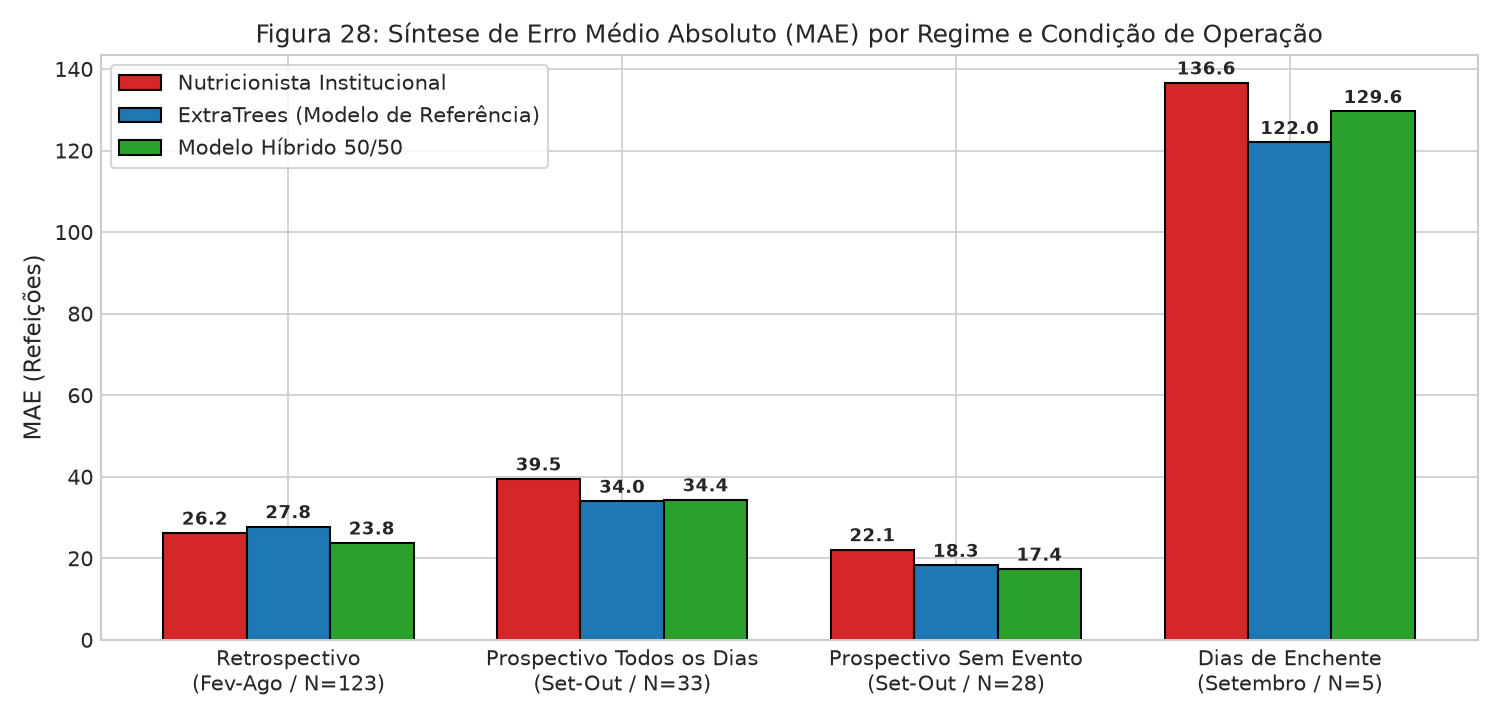

In [4]:
tabela_10 = pd.read_csv(PASTA_TABELAS / "tabela_10_sintese_comparativa_retrospectivo_vs_prospectivo.csv", sep=";")
print("=== TABELA 10: SÍNTESE COMPARATIVA DOS PERÍODOS ===")
display(tabela_10)
display(Image(filename=str(PASTA_FIGURAS / "figura_28_sintese_retrospectivo_vs_prospectivo.png")))


## 3. Margens, Previsão de Clima e Comparação Estatística
As margens foram calibradas em Fev-Ago e aplicadas sem recalibrar em Set-Out. O Cenário 3 usa somente previsões de clima arquivadas. A comparação entre métodos usa bootstrap pareado por semana: quando o intervalo de 95% inclui zero, não se declara vencedor.

In [5]:
print("=== TABELA 09: MARGENS EMPÍRICAS E COBERTURA ===")
display(pd.read_csv(PASTA_TABELAS / "tabela_09_margens_empiricas_quantis.csv", sep=";"))
print("=== TABELA 11: CENÁRIO 3 COM O MODELO CONGELADO ===")
display(pd.read_csv(PASTA_TABELAS / "tabela_11_cenario_3_clima_congelado.csv", sep=";")[["Recorte", "Metodo", "n_dias", "MAE", "RMSE", "WAPE_pct", "Sobra_Total_ref", "Deficit_Total_ref"]])
print("=== TABELA 12: COMPARAÇÃO PAREADA POR SEMANA ===")
display(pd.read_csv(PASTA_TABELAS / "tabela_12_comparacao_bootstrap_semanal.csv", sep=";"))


=== TABELA 09: MARGENS EMPÍRICAS E COBERTURA ===


,Politica,Quantil,Margem_ref,Cobertura_FevAgo_pct,Cobertura_SetOut_Todos_pct,Cobertura_SetOut_Sem_Evento_pct
0,IA Pura (ExtraTrees),P75,22.0,77.2,84.8,82.1
1,IA Pura (ExtraTrees),P85,35.0,87.8,93.9,92.9
2,IA Pura (ExtraTrees),P90,42.0,90.2,93.9,92.9
3,Modelo Híbrido 50/50,P75,13.0,76.4,75.8,71.4
4,Modelo Híbrido 50/50,P85,21.0,86.2,84.8,82.1
5,Modelo Híbrido 50/50,P90,27.0,90.2,87.9,85.7


=== TABELA 11: CENÁRIO 3 COM O MODELO CONGELADO ===


,Recorte,Metodo,n_dias,MAE,RMSE,WAPE_pct,Sobra_Total_ref,Deficit_Total_ref
0,Todos os dias (N=33),Nutricionista Institucional,33,39.48,65.46,21.90,972,331
1,Todos os dias (N=33),ExtraTrees Congelado - Cenário 2,33,34.00,56.86,18.86,722,400
2,Todos os dias (N=33),ExtraTrees Congelado - Cenário 3,33,34.39,56.48,19.08,702,433
3,Sem evento registrado (N=28),Nutricionista Institucional,28,22.14,30.46,11.10,289,331
4,Sem evento registrado (N=28),ExtraTrees Congelado - Cenário 2,28,18.29,22.58,9.16,112,400
5,Sem evento registrado (N=28),ExtraTrees Congelado - Cenário 3,28,19.54,23.70,9.79,114,433
6,Dias de enchente (N=5),Nutricionista Institucional,5,136.60,151.93,188.67,683,0
7,Dias de enchente (N=5),ExtraTrees Congelado - Cenário 2,5,122.00,135.95,168.51,610,0
8,Dias de enchente (N=5),ExtraTrees Congelado - Cenário 3,5,117.60,133.82,162.43,588,0


=== TABELA 12: COMPARAÇÃO PAREADA POR SEMANA ===


,Amostra,Comparacao,Diferenca_MAE,IC95_Inferior,IC95_Superior,Semanas,Conclusao
0,Fev-Ago walk-forward (todos os dias),ExtraTrees menos Nutricionista,1.58,-4.99,7.86,29,Sem diferença estatisticamente clara
1,Fev-Ago walk-forward (todos os dias),Híbrido menos Nutricionista,-2.43,-5.60,0.57,29,Sem diferença estatisticamente clara
2,Fev-Ago walk-forward (todos os dias),Híbrido menos ExtraTrees,-4.01,-7.82,-0.20,29,Diferença estatisticamente clara
3,Todos os dias (N=33) - congelado,ExtraTrees menos Nutricionista,-5.48,-12.17,-0.17,8,Diferença estatisticamente clara
4,Todos os dias (N=33) - congelado,Híbrido menos Nutricionista,-5.12,-7.92,-2.23,8,Diferença estatisticamente clara
5,Todos os dias (N=33) - congelado,Híbrido menos ExtraTrees,0.36,-3.53,4.79,8,Sem diferença estatisticamente clara
6,Sem evento registrado (N=28) - congelado,ExtraTrees menos Nutricionista,-3.86,-11.90,2.62,7,Sem diferença estatisticamente clara
7,Sem evento registrado (N=28) - congelado,Híbrido menos Nutricionista,-4.79,-8.23,-1.08,7,Diferença estatisticamente clara
8,Sem evento registrado (N=28) - congelado,Híbrido menos ExtraTrees,-0.93,-5.21,4.69,7,Sem diferença estatisticamente clara
